# 05 — Du patch à la patiente (Phase 7, version allégée)

**Portée réduite, assumée par manque de temps** (voir `PLAN.md`) : analyse sur les lames annotées des hôpitaux 0, 1, 3, 4 (40 des 50 lames) — **les 10 lames de l'hôpital 2 ne sont pas touchées ici**, pour ne pas mélanger cette illustration qualitative avec le test unique de la Phase 6. Les probabilités utilisées sont celles de la **référence simple de la Phase 3** (forêt aléatoire, couleur+texture, CPU, pas de GPU requis) — le CNN final de la Phase 6 n'était pas encore disponible au moment de cette phase ; la méthode est strictement la même quel que soit le modèle source.

Voir `PLAN.md` (Phase 7) et `outputs/rapport/07_patch_to_patient.md`.

In [1]:
# Colab/Kaggle : clone le depot si besoin et place le repertoire de travail dans notebooks/
# (sans effet en local : le depot est deja la, donc rien n'est clone ni deplace)
import os, subprocess, sys

REPO_URL = "https://github.com/YoucefLgr/Breast_Cancer.git"
EN_COLAB = "COLAB_GPU" in os.environ or "COLAB_RELEASE_TAG" in os.environ
EN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/input")

if EN_COLAB or EN_KAGGLE:
    repo_dir = "/content/Breast_Cancer" if EN_COLAB else "/kaggle/working/Breast_Cancer"
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", REPO_URL, repo_dir], check=True)
    os.chdir(os.path.join(repo_dir, "notebooks"))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../requirements.txt"], check=True)

print("Repertoire de travail :", os.getcwd())

Repertoire de travail : C:\Users\Youcef Lagraa\OneDrive\Bureau\Breast Cancer\Breast_Cancer\notebooks


In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

from src.utils import load_config, set_seed, detect_environment, save_metrics
from src.data import charger_metadonnees, charger_sous_echantillon, HOPITAL_LABEL
from src.features import extraire_features
from src.aggregation import carte_lame, plus_grande_zone_connectee, classe_lame_predite, TAILLE_PATCH_MM
from src.staging import verifier_regles_sur_officiel, comparer_stades

CFG = load_config()
set_seed(CFG["seed"])
print("Environnement :", detect_environment())
print(f"Taille physique d'un patch : {TAILLE_PATCH_MM:.4f} mm de côté "
      "(source : PCam, github.com/basveeling/pcam — 40x natif 0,243 µm/px, échantillonné à 10x)")

Environnement : local
Taille physique d'un patch : 0.0933 mm de côté (source : PCam, github.com/basveeling/pcam — 40x natif 0,243 µm/px, échantillonné à 10x)


## 1. Vérification des règles pN sur les classes officielles

Condition nécessaire avant d'aller plus loin : les règles codées doivent redonner **exactement** les 100 stades officiels de `stages.csv` à partir des classes officielles des lames.

In [3]:
stages = pd.read_csv("../donnees/stages.csv")
concordance = verifier_regles_sur_officiel(stages)
print(f"Concordance règles pN vs stades officiels : {concordance:.1%} (100 patientes)")

Concordance règles pN vs stades officiels : 100.0% (100 patientes)


## 2. Prédictions patch par patch (référence Phase 3)

124 variables (couleur + texture, `src/features.py`), forêt aléatoire — mêmes hyperparamètres que le modèle retenu en Phase 3 (AUC `val_ood` ≈ 0,90).

In [4]:
meta = charger_metadonnees(CFG)
df = charger_sous_echantillon(CFG)
X, ids, noms = extraire_features(df, cache=True, verbeux=True)

train = (df.split == "train").values
rf = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=5,
                            n_jobs=-1, random_state=CFG["seed"])
rf.fit(X[train], df.label.values[train])

auc_val = roc_auc_score(df.label.values[(df.split == "val_ood").values],
                        rf.predict_proba(X[(df.split == "val_ood").values])[:, 1])
print(f"Sanity-check — AUC val_ood : {auc_val:.4f} (repère Phase 3 : 0,898)")

proba_tout = rf.predict_proba(X)[:, 1]
probas = dict(zip(df.image_id.values.tolist(), proba_tout.tolist()))

Cache trouvé : 39,000 patchs déjà calculés (features_bins16.npz)
Sanity-check — AUC val_ood : 0.8975 (repère Phase 3 : 0,898)


## 3. Classe prédite pour chaque lame annotée (hôpitaux 0, 1, 3, 4)

Pour chaque lame, composantes connexes des patchs prédits positifs (parmi ceux disponibles dans le sous-échantillon), taille de la plus grande zone, classe déduite.

In [5]:
lames_off = stages[stages.patient.str.endswith(".tif")].copy()
lames_off["patient_id"] = lames_off.patient.str.extract(r"patient_(\d+)_node_(\d+)\.tif")[0].astype(int)
lames_off["node"] = lames_off.patient.str.extract(r"patient_(\d+)_node_(\d+)\.tif")[1].astype(int)

slide_info = meta.groupby("slide").agg(patient=("patient", "first"), node=("node", "first"),
                                        center=("center", "first")).reset_index()
lames_off_slim = lames_off[["patient_id", "node", "stage"]].rename(columns={"patient_id": "patient"})
slide_info = slide_info.merge(lames_off_slim, on=["patient", "node"], how="left")

resultats, classes_predites = [], {}
for _, row in slide_info.iterrows():
    if row.center == 2:
        continue   # hôpital 2 : non touché avant la Phase 6
    d = carte_lame(meta, row.slide, probas).dropna(subset=["proba"])
    if len(d) < 20:
        continue   # couverture trop faible dans le sous-échantillon
    zone = plus_grande_zone_connectee(d, colonne="proba", seuil=0.5)
    classe_pred = classe_lame_predite(zone["cote_equivalent_mm"])
    nom_fichier = f"patient_{int(row.patient):03d}_node_{int(row.node)}.tif"
    classes_predites[nom_fichier] = classe_pred
    resultats.append({"slide": row.slide, "patient": row.patient, "node": row.node,
                      "hopital": HOPITAL_LABEL[row.center], "n_patchs_disponibles": len(d),
                      "classe_officielle": row.stage, "classe_predite": classe_pred, **zone})

res = pd.DataFrame(resultats)
print(f"{len(res)} lames analysées (sur 40 hors hôpital 2)")
display(res[["slide", "hopital", "n_patchs_disponibles", "classe_officielle", "classe_predite",
             "n_patchs_zone_max", "cote_equivalent_mm"]])

print("\nMatrice de confusion (officiel vs prédit) :")
display(pd.crosstab(res.classe_officielle, res.classe_predite))
exactitude = (res.classe_officielle == res.classe_predite).mean()
print(f"Exactitude : {exactitude:.1%}")

40 lames analysées (sur 40 hors hôpital 2)


,slide,hopital,n_patchs_disponibles,classe_officielle,classe_predite,n_patchs_zone_max,cote_equivalent_mm
0,0,H0 (entraînement),683,itc,itc,1,0.0933
1,1,H0 (entraînement),692,micro,itc,3,0.1616
2,2,H0 (entraînement),602,micro,micro,5,0.2087
3,3,H0 (entraînement),2059,macro,micro,11,0.3095
4,4,H0 (entraînement),1089,macro,micro,8,0.2639
5,5,H0 (entraînement),512,macro,itc,4,0.1866
6,6,H0 (entraînement),496,itc,itc,1,0.0933
7,7,H0 (entraînement),252,itc,negative,0,0.0000
8,8,H0 (entraînement),2024,macro,micro,7,0.2469
9,9,H0 (entraînement),591,micro,itc,4,0.1866



Matrice de confusion (officiel vs prédit) :


classe_predite,itc,micro,negative
classe_officielle,,,
itc,10,0,4
macro,4,9,0
micro,12,1,0


Exactitude : 27.5%


## 4. Pourquoi l'exactitude est faible : la couverture du sous-échantillon, pas la méthode

Le sous-échantillon ne contient qu'une **fraction** des patchs de chaque lame (une centaine à quelques milliers, contre des dizaines de milliers au total par lame — voir Phase 0/2). L'analyse de composantes connexes a besoin d'une grille **dense** pour reconstituer la continuité spatiale d'une métastase : avec un échantillonnage partiel, de nombreux patchs intermédiaires (positifs comme négatifs) sont absents, et une zone réellement contiguë apparaît comme des points dispersés. Trois cartes ci-dessous (une par classe officielle) illustrent le problème très concrètement.

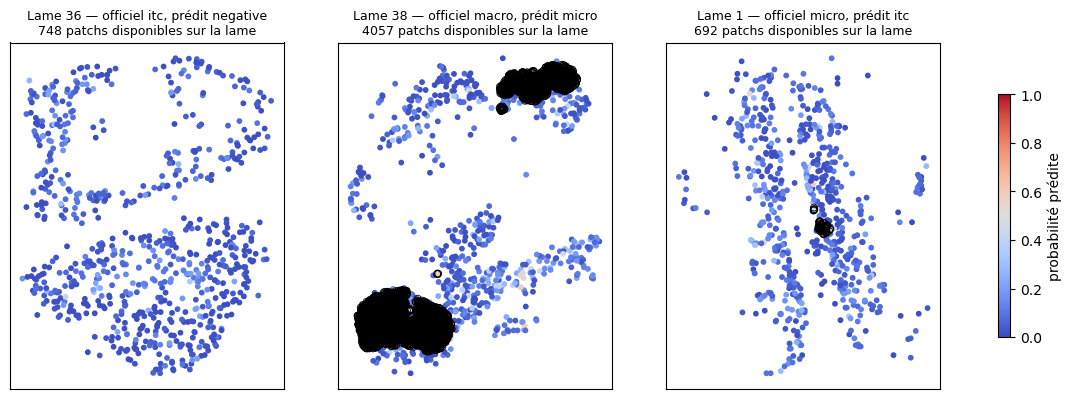

In [6]:
exemples = (res.sort_values("n_patchs_disponibles", ascending=False)
               .groupby("classe_officielle").head(1).sort_values("classe_officielle"))

fig, axes = plt.subplots(1, len(exemples), figsize=(5 * len(exemples), 4.5))
if len(exemples) == 1:
    axes = [axes]
for ax, (_, r) in zip(axes, exemples.iterrows()):
    d = carte_lame(meta, r.slide, probas).dropna(subset=["proba"])
    im = ax.scatter(d.x_coord, d.y_coord, c=d.proba, s=10, cmap="coolwarm", vmin=0, vmax=1)
    verite = d[d.label == 1]
    ax.scatter(verite.x_coord, verite.y_coord, facecolors="none", edgecolors="black", s=25, linewidths=0.6)
    ax.set_title(f"Lame {r.slide} — officiel {r.classe_officielle}, prédit {r.classe_predite}\n"
                f"{r.n_patchs_disponibles} patchs disponibles sur la lame", fontsize=9)
    ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=axes, label="probabilité prédite", shrink=0.7)
plt.savefig("../outputs/figures/08_cartes_lames.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Impact sur le stade pN de la patiente

Pour chaque patiente touchée par au moins une substitution (classe prédite à la place de la classe officielle, sur ses lames annotées), stade recalculé et comparé — en distinguant sous-staging (le plus grave) et sur-staging.

In [7]:
cmp = comparer_stades(stages, classes_predites)
display(cmp)

n_changes = int((cmp.stade_officiel != cmp.stade_avec_predictions).sum())
print(f"\nStades modifiés : {n_changes}/{len(cmp)} patientes touchées")
print(cmp.sens_erreur.value_counts())

,patiente,stade_officiel,stade_avec_predictions,sens_erreur
0,patient_004,pN0(i+),pN0(i+),inchange
1,patient_009,pN1mi,pN0(i+),sous_staging
2,patient_010,pN1mi,pN1mi,inchange
3,patient_012,pN1,pN1mi,sous_staging
4,patient_015,pN1,pN1mi,sous_staging
5,patient_016,pN1,pN1,inchange
6,patient_017,pN1,pN1,inchange
7,patient_020,pN1,pN1mi,sous_staging
8,patient_021,pN2,pN1,sous_staging
9,patient_022,pN1,pN1mi,sous_staging



Stades modifiés : 18/34 patientes touchées
sens_erreur
sous_staging    18
inchange        16
Name: count, dtype: int64


## 6. Sauvegarde des métriques

In [8]:
metrics = {
    "portee": "40 lames annotees sur 50 (hopitaux 0,1,3,4 ; hopital 2 exclu avant la Phase 6)",
    "modele_source": "reference Phase 3 (foret aleatoire, couleur+texture)",
    "taille_patch_mm": TAILLE_PATCH_MM,
    "source_resolution": "PCam (github.com/basveeling/pcam) : 40x natif 0.243 um/px, echantillonnage 10x",
    "concordance_regles_pN_officiel": concordance,
    "classification_lames": res.to_dict(orient="records"),
    "exactitude_classe_lame": float(exactitude),
    "impact_stade_pN": cmp.to_dict(orient="records"),
    "n_stades_modifies": n_changes,
    "limite_principale": (
        "Sous-echantillon = fraction des patchs par lame, pas la lame entiere : "
        "sous-estime fortement l'etendue des zones tumorales (composantes connexes sur "
        "grille eparse). Expliquerait la faible exactitude et le biais systematique vers "
        "le sous-staging observes ici."
    ),
}
print(save_metrics(metrics, "outputs/metrics/07_patch_to_patient.json"))

C:\Users\Youcef Lagraa\OneDrive\Bureau\Breast Cancer\Breast_Cancer\outputs\metrics\07_patch_to_patient.json


## 7. Lecture

Voir `outputs/rapport/07_patch_to_patient.md` : la méthode (règles pN, composantes connexes, classe de lame) est vérifiée et fonctionne — la limite dominante est la densité de patchs disponibles par lame, pas la logique d'agrégation elle-même. Avec les métadonnées complètes (455 954 patchs) ou des lames entières (option avancée du sujet), la même méthode donnerait une estimation nettement plus fidèle.